<div class="alert alert-block alert-info">
<b>✅ NOTA</b>: Este notebook se ha validado con un entorno creado en Anaconda con Python 3.13.15.
</div>

In [1]:
%run RCR_Bib_Mapas.ipynb

# Boletín 3 - Usando CLIPSPY (I): COOL

## Cargamos la ontología resultado del boletín anterior:

In [2]:
try:
    from owlready2 import *
except ImportError as e:
    !pip install Owlready2==0.51
    from owlready2 import *

In [3]:
onto_indiv = get_ontology('file://pract2.owl').load()

In [4]:
for i in onto_indiv.individuals():
    print(i.name)

La Lonja de la Seda 
https://www.visitvalencia.com/que-hacer-valencia/cultura-valenciana/monumentos-en-valencia/lonja-seda
https://cultural.valencia.es/es/monument/la-lonja-y-consulado-del-mar
Museo del Colegio Arte Mayor de la Seda
https://www.museodelasedavalencia.com/museo
https://www.visitvalencia.com/que-hacer-valencia/cultura-valenciana/museos-en-valencia/museo-seda
https://cultural.valencia.es/es/museu/museo-del-colegio-arte-mayor-de-la-seda
Palacio de Tamarit  
https://www.visitvalencia.com/que-hacer-valencia/rutas-por-la-ciudad/ruta-de-la-seda
https://cultural.valencia.es/es/ruta/ruta-de-la-seda
Centro de Artesanía de la Comunidad Valenciana  
https://www.centroartesaniacv.com
https://www.visitvalencia.com/que-hacer-valencia/cultura-valenciana/museos-en-valencia/centro-artesania-comunidad-valenciana
 Museo Nacional de Cerámica y Artes Suntuarias ubicado en el Palacio del Marqués de Dos Aguas 
https://www.visitvalencia.com/que-hacer-valencia/cultura-valenciana/museos-en-valenci

### La ontología [FOAF](http://xmlns.com/foaf/0.1/)

[**FOAF**](http://xmlns.com/foaf/0.1/) (*Friend Of A Friend*)  es una pequeña ontología que se desarrolló para permitir representar las inter-relaciones entre personas.

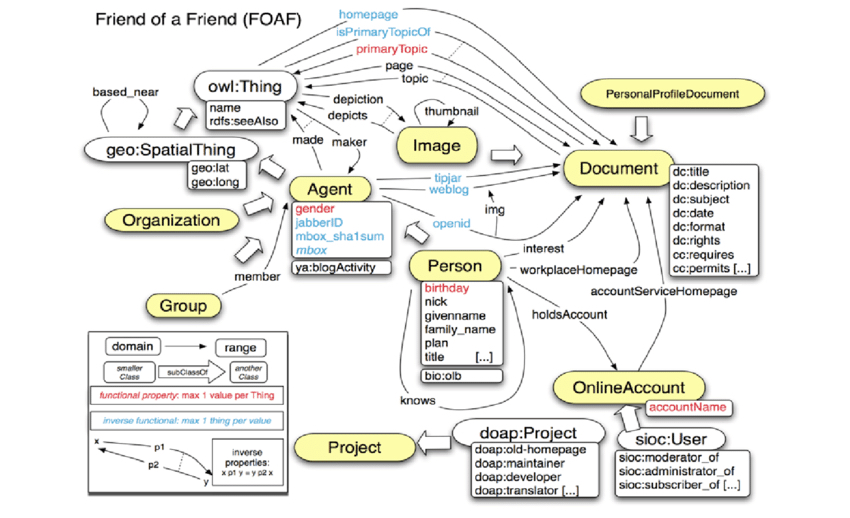

[**FOAF en WebOWL**](https://service.tib.eu/webvowl/#iri=https://service.tib.eu/webvowl/#iri=http://xmlns.com/foaf/0.1/)

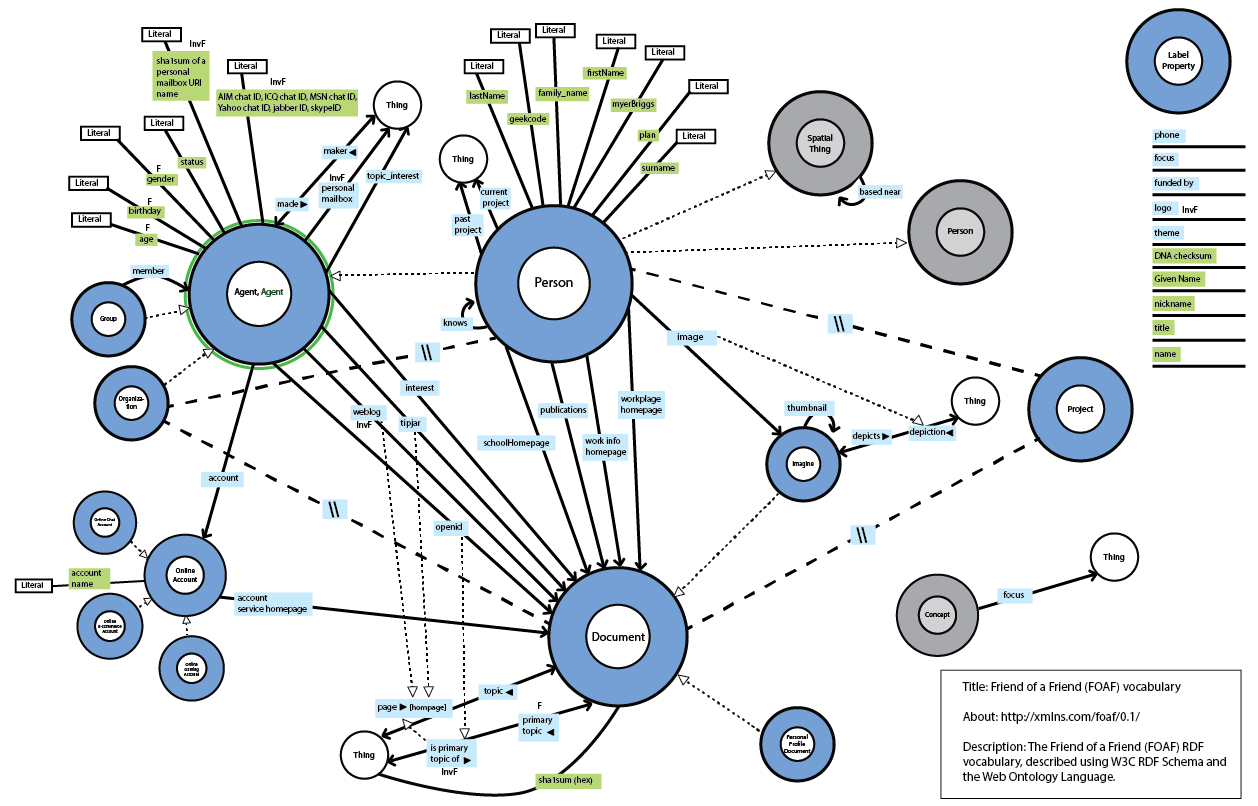

**Cargamos FOAF**

In [5]:
onto_foaf = get_ontology('http://xmlns.com/foaf/0.1/')
onto_foaf.load()

* Owlready2 * WARNING: DataProperty http://xmlns.com/foaf/0.1/name belongs to more than one entity types: [owl.DatatypeProperty, rdf-schema.label]; I'm trying to fix it...


get_ontology("http://xmlns.com/foaf/0.1/")

In [6]:
for i in onto_foaf.classes():
    print(i)

rdf-schema.Class
0.1.Person
1.6.Person
0.1.Agent
1.6.Agent
contact.Person
wgs84_pos.SpatialThing
0.1.Document
0.1.Organization
0.1.Project
1.6.Document
1.6.Organization
0.1.Group
1.6.Agent-3
1.6.Project
0.1.Image
0.1.PersonalProfileDocument
0.1.OnlineAccount
0.1.OnlineGamingAccount
0.1.OnlineEcommerceAccount
0.1.OnlineChatAccount


In [7]:
foaf = get_namespace(onto_foaf.base_iri)

### Añadir FOAF a las ontologías importadas de nuestra ontología

In [8]:
onto_indiv.imported_ontologies.append(onto_foaf)

### Ejemplo de creación de individuos con FOAF

In [9]:
with onto_indiv:
    individual = foaf.Person('Pepe')
    print(individual.name)

Pepe


In [10]:
with onto_indiv:
    for i in onto_foaf.properties():
        ###print(i.domain)
        if (individual.is_a[0] in i.domain):
            print(i, ' - Range: ', i.range)

0.1.geekcode  - Range:  [None]
0.1.firstName  - Range:  [None]
0.1.surname  - Range:  [None]
0.1.family_name  - Range:  [None]
0.1.plan  - Range:  [None]
0.1.img  - Range:  [0.1.Image]
0.1.myersBriggs  - Range:  [None]
0.1.workplaceHomepage  - Range:  [0.1.Document]
0.1.workInfoHomepage  - Range:  [0.1.Document]
0.1.schoolHomepage  - Range:  [0.1.Document]
0.1.knows  - Range:  [0.1.Person]
0.1.interest  - Range:  [0.1.Document]
0.1.topic_interest  - Range:  [owl.Thing]
0.1.publications  - Range:  [0.1.Document]
0.1.currentProject  - Range:  [owl.Thing]
0.1.pastProject  - Range:  [owl.Thing]


| Ejercicio 1:|
| -----------:|
| Definir una función que reciba una ontología OWL como la que estamos usando y cree una instancia de la clase `foaf.Person()` pidiéndole al usuario sus datos principales para rellenar dicha instancia. |

| Ejercicio 2:|
| -----------:|
| Guardad el estado de la ontología actual en un fichero llamado `pract3_<apellido_nombre>.owl`. |

## CLIPS

Revisar el notebook `Notas sobre COOL y CLIPSPY.ipynb`. 

In [1]:
try:
    import clips
except ImportError as e:
    !pip install clipspy==1.0.6
    import clips

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 3.1 MB/s  0:00:00 eta 0:00:01


### Creación de clases COOL

Se crea una cadena de caracteres para cada clase, y se añade al entorno con el método ***build(<clase>)***.

Tipos de datos en CLIPS: 

    EXTERNAL_ADDRESS = 5
    
    FACT_ADDRESS = 6
    
    FLOAT = 0
    
    INSTANCE_ADDRESS = 7
    
    INSTANCE_NAME = 8
    
    INTEGER = 1
    
    MULTIFIELD = 4
    
    STRING = 3
    
    SYMBOL = 2

Ejemplo de la creación de clases en **COOL** (para la versión de CLIPS 6.4 en adelante):

In [15]:
sPersonas = """
(defclass PERSONAS (is-a USER)
    (slot nombre (type STRING))
    (slot edad (type INTEGER)(range 0 110))
    (multislot apellidos (type STRING)(cardinality 1 2))
    (slot DNI (type NUMBER))
    (slot sexo (type SYMBOL)(allowed-values M H)))
"""

sHombres = """
(defclass HOMBRES (is-a PERSONAS)
    (slot sexo (default H)))
"""

sMujeres = """
(defclass MUJERES (is-a PERSONAS)
    (slot sexo (default M)))
"""

sVehiculos = """
(defclass VEHICULOS (is-a USER)
    (slot matricula (type SYMBOL))
    (slot propietario (type INSTANCE-NAME)
			(allowed-classes PERSONAS)))
"""

Añadimos a un entorno nuevo de CLIPS cada una de las cadenas que definen las clases:

In [16]:
env = clips.Environment()

env.build(sPersonas)
env.build(sHombres)
env.build(sMujeres)
env.build(sVehiculos)

### Creación de instancias COOL

Se define la instancia por medio de una cadena de caracteres, indicando (entre paréntesis como todas las órdenes y datos de CLIPS) la instrucción `make-instance` seguido del identificador de la instancia y la clase de la que voy a crearla, así como los valores que se quieran establecer de los slots definidos:

In [17]:
sEva = """
   (make-instance [eva] of MUJERES (nombre "Eva")
			(apellidos "Hernandez" "Garcia"))
"""

sJuan = """
(make-instance [juan] of HOMBRES (nombre "Juan")
			(apellidos "Fernandez" "Lopez"))
"""

sV1 = """
(make-instance [v1] of VEHICULOS (propietario [juan])(matricula 3333CBS))
"""

sV2 = """
(make-instance [v2] of VEHICULOS (propietario [eva]))
"""

Enviamos cada una de las cadenas al entorno CLIPS para que las evalúe.

In [18]:
env.eval(sEva)
env.eval(sJuan)
env.eval(sV1)
env.eval(sV2)

'v2'

In [19]:
for inst in env.instances():
    print(inst)

[eva] of MUJERES (nombre "Eva") (edad 0) (apellidos "Hernandez" "Garcia") (DNI 0) (sexo M)
[juan] of HOMBRES (nombre "Juan") (edad 0) (apellidos "Fernandez" "Lopez") (DNI 0) (sexo H)
[v1] of VEHICULOS (matricula 3333CBS) (propietario [juan])
[v2] of VEHICULOS (matricula nil) (propietario [eva])


| Ejercicio 3:|
| -----------:|
| Definir la estructura de clases COOL necesaria para representar la clase `Ruta` definida en el Boletín anterior en la ontología OWL desarrollada. Esta estructura de clases deberá incluir como mínimo tres clases: la de la `Ruta`, otra para los edificios o monumentos que formen parte de la ruta, y una más para los tipos de turismo. |

| Ejercicio 4:|
| -----------:|
| Definir una clase COOL para poder representar a los Usuarios del sistema. Esta clase debe incluir, aparte de los slots que permitan almacenar los datos personales del ususario, aquellos para almacenar la lista de tipos de turismo que le interesan al usuario y una lista de pares (`instance_name` `valoración`) donde se guardará el nombre de la instancia de la ruta realizada por el usuario, así como la valoración que dicho usuario le otorgue a la ruta (valor entero entre 0 y 10). |

| Ejercicio 5:|
| -----------:|
| Realizar una función que reciba como parámetro una ontología como la que estamos trabajando y un entorno COOL con un modelo de clases como el que acabamos de realizar, y cree las instancias de dichas clases CLIPS que permitan representar la información de la ontología pasada como parámetro. La función acabará devolviendo el entorno actualizado. |

| Ejercicio 6:|
| -----------:|
| Usar la función anterior para crear la estructura de instancias de COOL que nos permitan representar la información de la ontología que tenemos. |

| Ejercicio 7:|
| -----------:|
| Guarda en un fichero llamado `pract3_cool_clases.txt` las clases generadas en **COOL** y en un fichero llamado `pract3_cool_instances.txt` las instancias generadas para el mismo. |